# Lab Khai phá dữ liệu - Heart Disease (Câu 5)
**Trần Minh Tấn - 6451071071**

## Cell 1: Cài đặt và kết nối dữ liệu

In [1]:
!pip install -q gdown

import gdown, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

HO_TEN = "Trần Minh Tấn"
MSSV   = "6451071071"

def info(cau=""):
    print("=" * 55)
    print(f"Họ tên : {HO_TEN}")
    print(f"MSSV   : {MSSV}")
    if cau:
        print(f"Nội dung: {cau}")
    print("=" * 55)

info("Cài đặt và kết nối dữ liệu Heart Disease")

FILE_ID = "10N9jGzMn-MagDWXORdP-qIpwC3omZJHb"   # heart.csv
gdown.download(id=FILE_ID, output="heart.csv", quiet=False)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Cài đặt và kết nối dữ liệu Heart Disease


Downloading...
From: https://drive.google.com/uc?id=10N9jGzMn-MagDWXORdP-qIpwC3omZJHb
To: /content/heart.csv
100%|██████████| 11.0k/11.0k [00:00<00:00, 22.8MB/s]


'heart.csv'

## Cell 2: Câu 5a - Nhập dữ liệu, xóa dòng trống, đổi tên cột

In [2]:
info("Câu 5a - Nhập dữ liệu, xóa dòng trống, đổi tên cột")

df = pd.read_csv("heart.csv", encoding="utf-8-sig")   # utf-8-sig để bỏ ký tự BOM ở tên cột đầu
print("Kích thước ban đầu:", df.shape)

# Xóa các dòng chứa dữ liệu trống
df = df.dropna().reset_index(drop=True)
print("Kích thước sau khi xóa dòng trống:", df.shape)

# Đổi tên cột
df.columns = ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
              'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
              'exercise_induced_angina', 'st_depression', 'st_slope',
              'num_major_vessels', 'thalassemia', 'target']

print("Các cột sau khi đổi tên:", list(df.columns))
df.head()

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 5a - Nhập dữ liệu, xóa dòng trống, đổi tên cột
Kích thước ban đầu: (303, 14)
Kích thước sau khi xóa dòng trống: (303, 14)
Các cột sau khi đổi tên: ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia', 'target']


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Cell 3: Câu 3 - Độ tương đồng Pearson

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 3 - Độ tương đồng Pearson


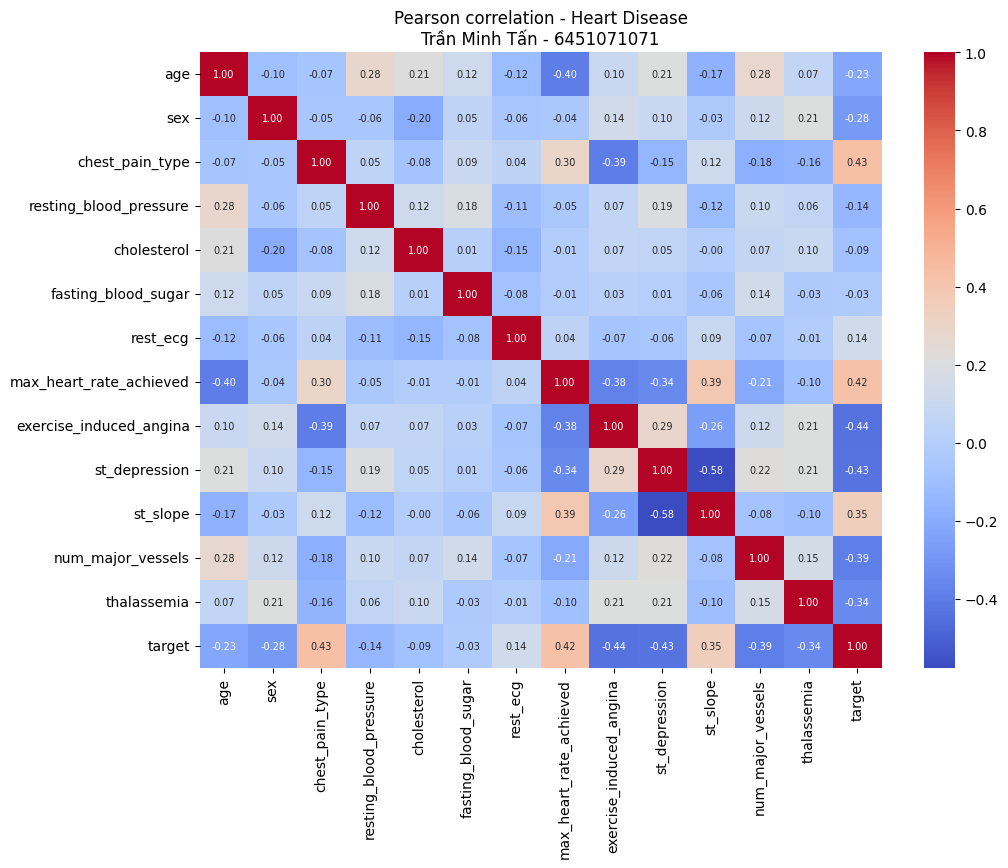

st_slope - st_depression = -0.58

Cột bị loại (|r| > 0.8): Không có cột nào


In [3]:
info("Câu 3 - Độ tương đồng Pearson")

corr = df.corr(method="pearson")

plt.figure(figsize=(11,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", annot_kws={"size":7})
plt.title(f"Pearson correlation - Heart Disease\n{HO_TEN} - {MSSV}")
plt.show()

# Xét tương đồng giữa các thuộc tính (không tính cột target)
feat_corr = df.drop(columns="target").corr(method="pearson")

THRESH = 0.8
to_drop = set()
for i in range(len(feat_corr.columns)):
    for j in range(i):
        r = feat_corr.iloc[i, j]
        if abs(r) > 0.4:
            print(f"{feat_corr.columns[i]} - {feat_corr.columns[j]} = {r:.2f}")
        if abs(r) > THRESH:
            to_drop.add(feat_corr.columns[i])

print(f"\nCột bị loại (|r| > {THRESH}):", list(to_drop) if to_drop else "Không có cột nào")
df = df.drop(columns=list(to_drop))

## Cell 4: Câu 4 - Tách thuộc tính thường và thuộc tính quyết định

In [4]:
info("Câu 4 - Tách thuộc tính thường và thuộc tính quyết định (target)")

X = df.drop(columns="target")   # thuộc tính bình thường
y = df["target"]                # thuộc tính quyết định

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("\nPhân bố nhãn target:")
print(y.value_counts())

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 4 - Tách thuộc tính thường và thuộc tính quyết định (target)
Kích thước X: (303, 13)
Kích thước y: (303,)

Phân bố nhãn target:
target
1    165
0    138
Name: count, dtype: int64


## Cell 5: Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector

In [5]:
info("Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector")

cat_cols = X.select_dtypes(exclude=np.number).columns
print("Các cột không phải dạng số:", list(cat_cols) if len(cat_cols) else "Không có (toàn bộ đã là dạng số)")

if len(cat_cols):
    X = pd.get_dummies(X, columns=cat_cols, dtype=int)

print("Kích thước X sau xử lý:", X.shape)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector
Các cột không phải dạng số: Không có (toàn bộ đã là dạng số)
Kích thước X sau xử lý: (303, 13)


## Cell 6: Câu 6 - Tách dữ liệu thành tập huấn luyện (70%) và kiểm thử (30%)

In [6]:
info("Câu 6 - Chia dữ liệu huấn luyện 70% và kiểm thử 30%")

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 6 - Chia dữ liệu huấn luyện 70% và kiểm thử 30%
X_train: (212, 13) | y_train: (212,)
X_test : (91, 13) | y_test : (91,)


## Cell 7: Câu 7 - Cây ID3

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 7 - Cây ID3
Accuracy ID3: 0.7253
              precision    recall  f1-score   support

           0       0.65      0.83      0.73        41
           1       0.82      0.64      0.72        50

    accuracy                           0.73        91
   macro avg       0.74      0.73      0.73        91
weighted avg       0.75      0.73      0.72        91



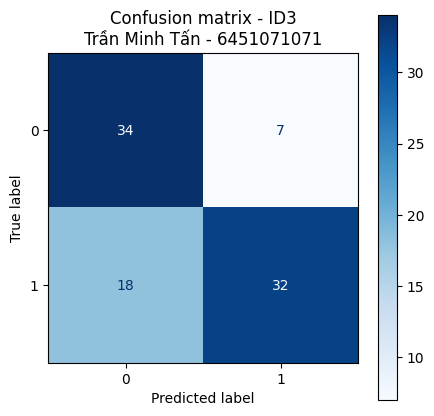

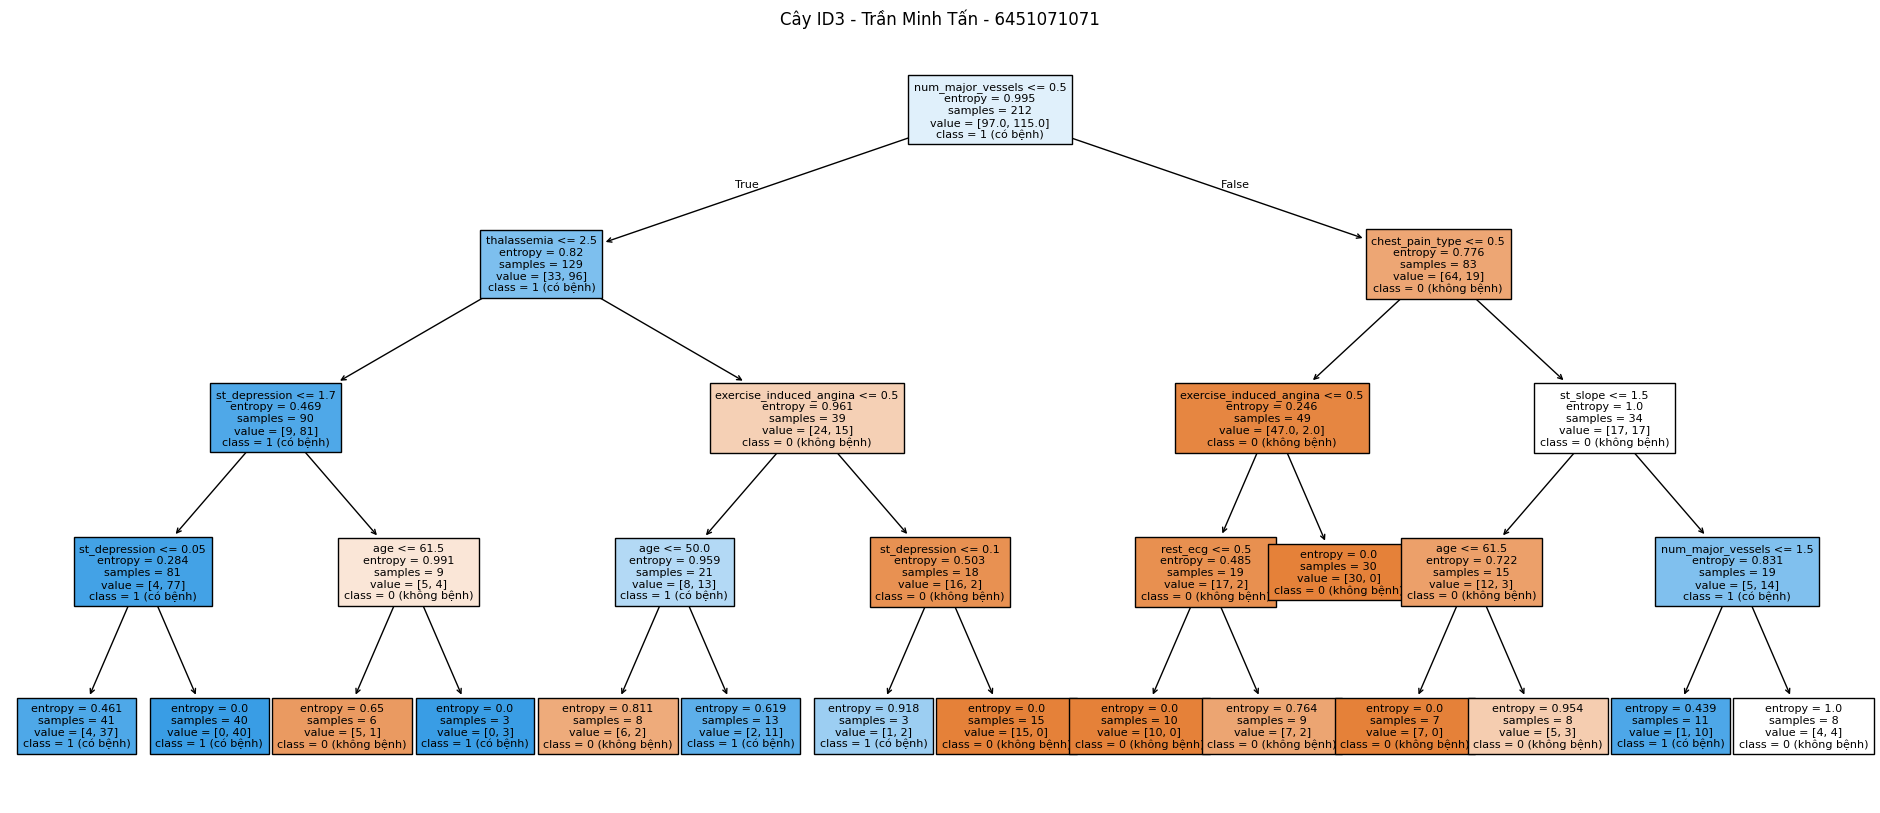

In [7]:
info("Câu 7 - Cây ID3")

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score)

# ID3 dùng entropy (information gain)
id3 = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
id3.fit(X_train, y_train)
pred_id3 = id3.predict(X_test)

print("Accuracy ID3:", round(accuracy_score(y_test, pred_id3), 4))
print(classification_report(y_test, pred_id3, zero_division=0))

fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_id3, labels=[0,1], cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix - ID3\n{HO_TEN} - {MSSV}")
plt.show()

plt.figure(figsize=(24,10))
plot_tree(id3, feature_names=X_train.columns, class_names=["0 (không bệnh)", "1 (có bệnh)"],
          filled=True, fontsize=8)
plt.title(f"Cây ID3 - {HO_TEN} - {MSSV}")
plt.show()

## Cell 8: Câu 8 - Cây CART

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 8 - Cây CART
Accuracy CART: 0.7253
              precision    recall  f1-score   support

           0       0.65      0.83      0.73        41
           1       0.82      0.64      0.72        50

    accuracy                           0.73        91
   macro avg       0.74      0.73      0.73        91
weighted avg       0.75      0.73      0.72        91



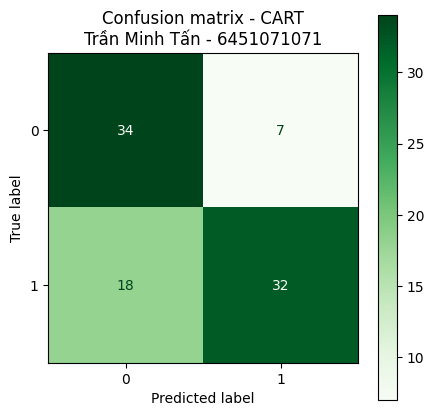

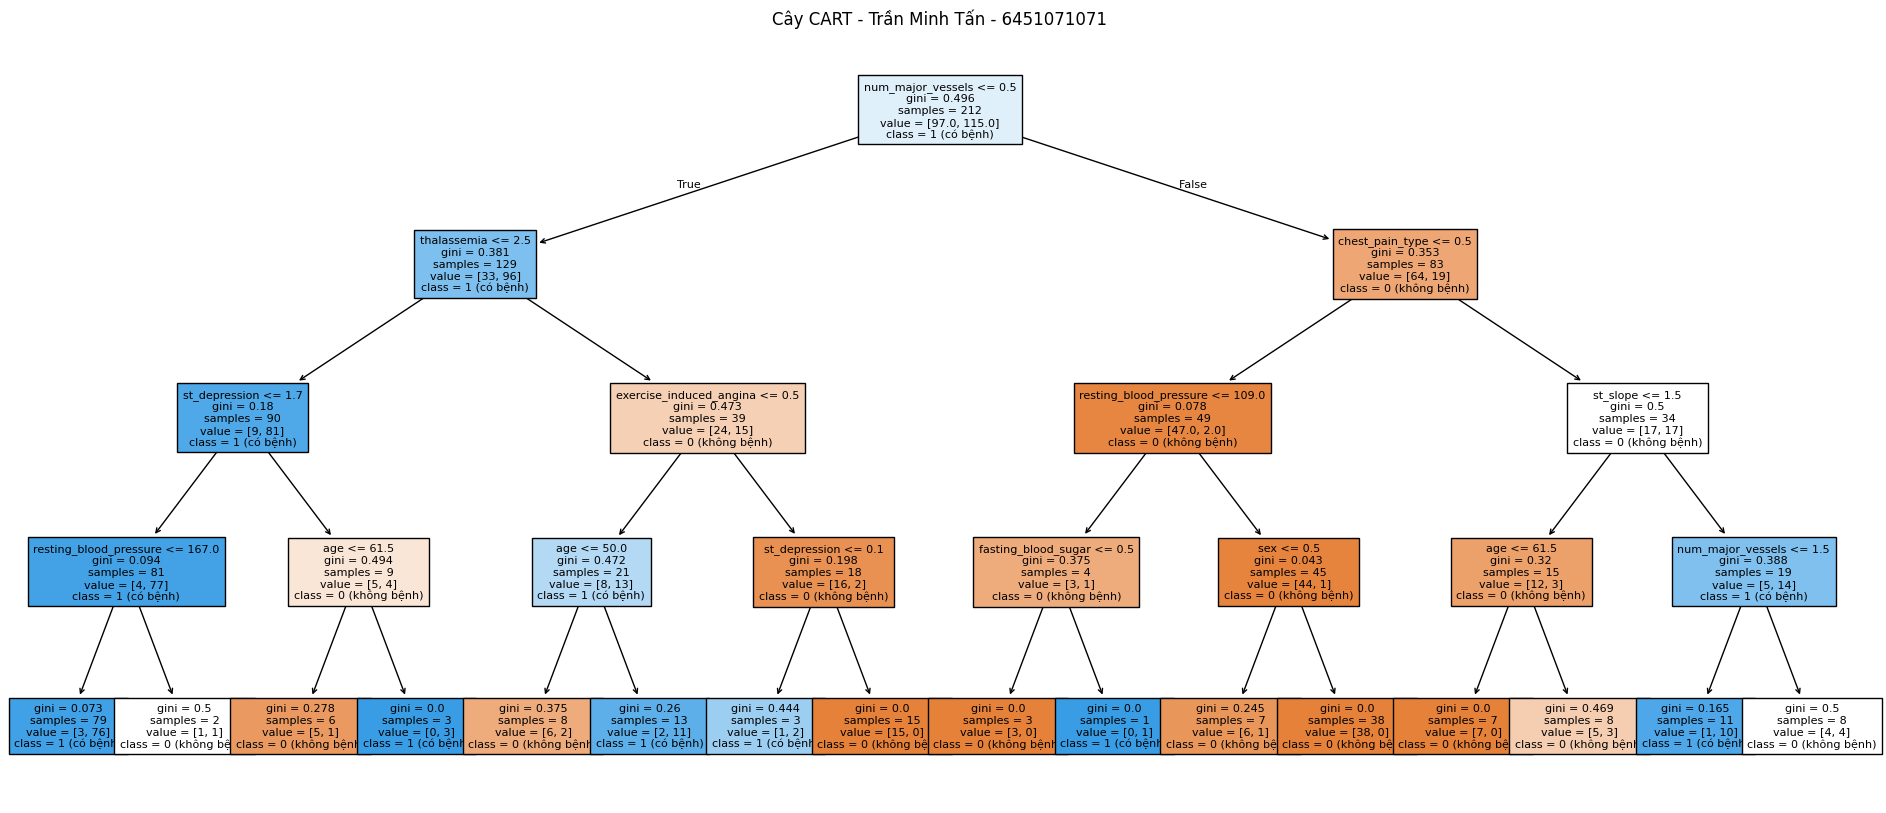

In [8]:
info("Câu 8 - Cây CART")

# CART dùng gini
cart = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42)
cart.fit(X_train, y_train)
pred_cart = cart.predict(X_test)

print("Accuracy CART:", round(accuracy_score(y_test, pred_cart), 4))
print(classification_report(y_test, pred_cart, zero_division=0))

fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_cart, labels=[0,1], cmap="Greens", ax=ax)
ax.set_title(f"Confusion matrix - CART\n{HO_TEN} - {MSSV}")
plt.show()

plt.figure(figsize=(24,10))
plot_tree(cart, feature_names=X_train.columns, class_names=["0 (không bệnh)", "1 (có bệnh)"],
          filled=True, fontsize=8)
plt.title(f"Cây CART - {HO_TEN} - {MSSV}")
plt.show()

## Cell 9: Câu 9 - Naive Bayes

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 9 - Naive Bayes
Accuracy Naive Bayes: 0.8352
              precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



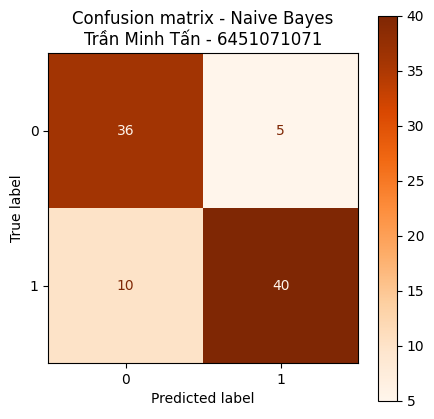

In [9]:
info("Câu 9 - Naive Bayes")

from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)

print("Accuracy Naive Bayes:", round(accuracy_score(y_test, pred_nb), 4))
print(classification_report(y_test, pred_nb, zero_division=0))

fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_nb, labels=[0,1], cmap="Oranges", ax=ax)
ax.set_title(f"Confusion matrix - Naive Bayes\n{HO_TEN} - {MSSV}")
plt.show()

## Cell 10: Câu 10 - So sánh kết quả các mô hình

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 10 - So sánh kết quả các mô hình


,Accuracy,Precision,Recall,F1-score
Mô hình,,,,
ID3,0.7253,0.8205,0.64,0.7191
CART,0.7253,0.8205,0.64,0.7191
Naive Bayes,0.8352,0.8889,0.80,0.8421


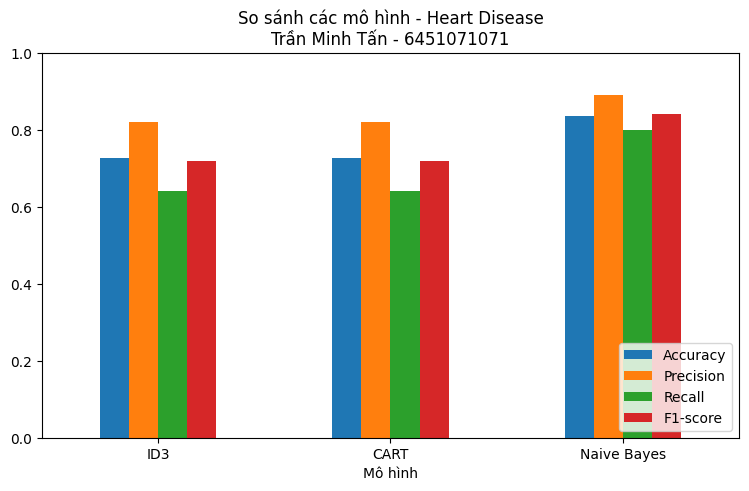

Mô hình có Accuracy cao nhất: Naive Bayes (0.8352)


In [10]:
info("Câu 10 - So sánh kết quả các mô hình")

results = []
for name, pred in [("ID3", pred_id3), ("CART", pred_cart), ("Naive Bayes", pred_nb)]:
    results.append({
        "Mô hình":   name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred, zero_division=0),
        "F1-score":  f1_score(y_test, pred, zero_division=0),
    })

res = pd.DataFrame(results).set_index("Mô hình").round(4)
display(res)

res.plot(kind="bar", figsize=(9,5), ylim=(0,1))
plt.title(f"So sánh các mô hình - Heart Disease\n{HO_TEN} - {MSSV}")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

best = res["Accuracy"].idxmax()
print(f"Mô hình có Accuracy cao nhất: {best} ({res.loc[best,'Accuracy']})")